# Phân tích nghỉ việc nhân sự — IBM HR Analytics Employee Attrition & Performance
**Mid-term 2 – Project 5 | Khoa học dữ liệu trong kinh tế và kinh doanh (NEU)**

Nhóm: Nguyễn Thu Trang (11248108), Hoàng Minh Ngọc (11247707), Tạ Bùi Vân Anh (11244614), Nguyễn Hoàng Hà Anh (11242469), Nguyễn Quang Huy

GitHub: https://github.com/trangthu171106/ibm-hr-attrition-analysis

**Câu hỏi kinh doanh:** Nhân viên nào có nguy cơ nghỉ việc, vì sao, và doanh nghiệp nên can thiệp ở đâu để giảm chi phí nghỉ việc?

Notebook đi theo 4 giai đoạn của đề bài:
1. Thu thập và đánh giá dữ liệu ban đầu
2. Tiền xử lý và làm sạch dữ liệu
3. Phân tích, kiểm định giả thuyết, trực quan hóa (+ mô hình dự báo rủi ro)
4. Đánh giá tác động và khuyến nghị

> Chạy được bằng **Runtime → Run all** trên Google Colab. Dữ liệu tự tải từ kho GitHub chính thức của IBM nếu không có file cục bộ.

In [1]:
# ============================================================
# 0. THIẾT LẬP MÔI TRƯỜNG: thư viện, bảng màu, hàm tiện ích
# ============================================================
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             classification_report, recall_score, precision_score, f1_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Bảng màu đã kiểm tra an toàn cho người mù màu: xanh = Ở lại, cam = Nghỉ việc
C_STAY, C_LEAVE, C_GREY, C_INK = "#2a78d6", "#eb6834", "#b8b6ae", "#52514e"
CMAP_RATE = LinearSegmentedColormap.from_list("rate", ["#fcfcfb", "#f6c7ad", "#eb6834", "#a8401a"])
CMAP_DIV  = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f3a17c", "#b4451a"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    # Lưu hình vào thư mục figures/ để dùng trong báo cáo PDF
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def attr_rate(frame, col):
    # Tỷ lệ nghỉ việc + cỡ mẫu theo từng nhóm của biến col
    g = frame.groupby(col, observed=True)["AttritionFlag"].agg(["mean", "size"])
    g.columns = ["rate", "n"]
    return g

def cramers_v(table):
    # Cramér's V: độ lớn hiệu ứng cho kiểm định Chi-bình phương (0 = không liên hệ, 1 = hoàn toàn)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))
def bonferroni(p):
    # Hiệu chỉnh Bonferroni: nhân p-value với số kiểm định m (tối đa 1) — tương đương so p với α/m
    p = np.asarray(p, dtype=float)
    return np.minimum(p * len(p), 1)

print("Môi trường sẵn sàng.")

Môi trường sẵn sàng.


# GIAI ĐOẠN 1 — Thu thập và đánh giá dữ liệu ban đầu
## 1.1 Nguồn dữ liệu
Bộ dữ liệu **IBM HR Analytics Employee Attrition & Performance** (Kaggle, tác giả pavansubhasht) do các nhà khoa học dữ liệu IBM tạo ra (*fictional data*) để mô phỏng hồ sơ nhân sự. Gồm **1 file CSV** `WA_Fn-UseC_-HR-Employee-Attrition.csv`, không cần ghép bảng.

**Mục tiêu bài toán:** biến mục tiêu `Attrition` (Yes/No) → bài toán *phân loại nhị phân* và *phân tích nguyên nhân*.

In [2]:
# 1.1 Tải dữ liệu: ưu tiên file cục bộ (repo GitHub của nhóm), nếu không có thì tải từ kho chính thức của IBM
LOCAL = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
URL = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
src = LOCAL if os.path.exists(LOCAL) else URL

# encoding='utf-8-sig': an toàn nếu file có ký tự BOM ở đầu (thường gặp khi xuất CSV từ Excel)
raw = pd.read_csv(src, encoding="utf-8-sig")
print("Nguồn:", src)
print("Kích thước:", raw.shape, "→", raw.shape[0], "quan sát,", raw.shape[1], "thuộc tính")
raw.head()

Nguồn: WA_Fn-UseC_-HR-Employee-Attrition.csv
Kích thước: (1470, 35) → 1470 quan sát, 35 thuộc tính


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1.2 Từ điển dữ liệu
Nhiều cột số thực chất là **thang đo thứ bậc (ordinal)** đã được mã hóa; cần hiểu đúng trước khi xử lý.

In [3]:
# 1.2 Từ điển dữ liệu: phân nhóm thuộc tính theo bản chất (không chỉ theo kiểu dữ liệu máy đọc)
dictionary = pd.DataFrame([
    ("Biến mục tiêu", "Attrition", "Yes/No – nhân viên đã nghỉ việc"),
    ("Nhân khẩu học", "Age, Gender, MaritalStatus, DistanceFromHome", "Tuổi, giới tính, hôn nhân, khoảng cách nhà"),
    ("Học vấn", "Education (1-5), EducationField", "1=Below College … 5=Doctor"),
    ("Công việc", "Department, JobRole, JobLevel (1-5), BusinessTravel, OverTime", "Vị trí, cấp bậc, công tác, làm thêm giờ"),
    ("Thu nhập", "MonthlyIncome, PercentSalaryHike, StockOptionLevel (0-3)", "Lương tháng, % tăng lương, mức cổ phiếu"),
    ("Thu nhập (nghi vấn)", "DailyRate, HourlyRate, MonthlyRate", "Ý nghĩa không được mô tả – sẽ kiểm tra"),
    ("Khảo sát (1-4)", "EnvironmentSatisfaction, JobSatisfaction, RelationshipSatisfaction, JobInvolvement, WorkLifeBalance", "1=Low/Bad … 4=Very High/Best"),
    ("Hiệu suất", "PerformanceRating (1-4), TrainingTimesLastYear", "1=Low … 4=Outstanding"),
    ("Thâm niên", "TotalWorkingYears, NumCompaniesWorked, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager", "Đơn vị: năm"),
    ("Kỹ thuật", "EmployeeNumber, EmployeeCount, Over18, StandardHours", "Mã định danh và cột hằng"),
], columns=["Nhóm", "Thuộc tính", "Ghi chú"])
dictionary

,Nhóm,Thuộc tính,Ghi chú
0,Biến mục tiêu,Attrition,Yes/No – nhân viên đã nghỉ việc
1,Nhân khẩu học,"Age, Gender, MaritalStatus, DistanceFromHome","Tuổi, giới tính, hôn nhân, khoảng cách nhà"
2,Học vấn,"Education (1-5), EducationField",1=Below College … 5=Doctor
3,Công việc,"Department, JobRole, JobLevel (1-5), BusinessT...","Vị trí, cấp bậc, công tác, làm thêm giờ"
4,Thu nhập,"MonthlyIncome, PercentSalaryHike, StockOptionL...","Lương tháng, % tăng lương, mức cổ phiếu"
5,Thu nhập (nghi vấn),"DailyRate, HourlyRate, MonthlyRate",Ý nghĩa không được mô tả – sẽ kiểm tra
6,Khảo sát (1-4),"EnvironmentSatisfaction, JobSatisfaction, Rela...",1=Low/Bad … 4=Very High/Best
7,Hiệu suất,"PerformanceRating (1-4), TrainingTimesLastYear",1=Low … 4=Outstanding
8,Thâm niên,"TotalWorkingYears, NumCompaniesWorked, YearsAt...",Đơn vị: năm
9,Kỹ thuật,"EmployeeNumber, EmployeeCount, Over18, Standar...",Mã định danh và cột hằng


In [4]:
# 1.3 Rà soát hiện trạng: kiểu dữ liệu, số giá trị duy nhất, tỷ lệ thiếu cho từng trường
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "ví dụ": raw.iloc[0],
})
print("Tổng số ô thiếu:", int(raw.isna().sum().sum()))
print("Số cột số:", raw.select_dtypes("number").shape[1], "| Số cột chữ:", raw.select_dtypes(exclude="number").shape[1])
profile.sort_values("n_unique")

Tổng số ô thiếu: 0
Số cột số: 26 | Số cột chữ: 9


,dtype,n_unique,missing,missing_%,ví dụ
EmployeeCount,int64,1,0,0.0,1
Over18,str,1,0,0.0,Y
StandardHours,int64,1,0,0.0,80
Attrition,str,2,0,0.0,Yes
OverTime,str,2,0,0.0,Yes
PerformanceRating,int64,2,0,0.0,3
Gender,str,2,0,0.0,Female
BusinessTravel,str,3,0,0.0,Travel_Rarely
Department,str,3,0,0.0,Sales
MaritalStatus,str,3,0,0.0,Single


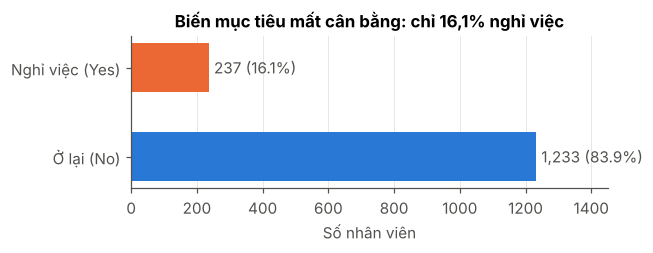

Tỷ lệ mất cân bằng ≈ 5.2 : 1


In [5]:
# 1.4 Phân phối biến mục tiêu: kiểm tra mất cân bằng lớp
counts = raw["Attrition"].value_counts()
share = raw["Attrition"].value_counts(normalize=True)
fig, ax = plt.subplots(figsize=(6, 2.4))
ax.barh(["Ở lại (No)", "Nghỉ việc (Yes)"], [counts["No"], counts["Yes"]],
        color=[C_STAY, C_LEAVE], height=0.55)
for i, k in enumerate(["No", "Yes"]):
    ax.text(counts[k] + 15, i, f"{counts[k]:,} ({share[k]:.1%})", va="center", color=C_INK)
ax.set_xlim(0, 1450); ax.set_xlabel("Số nhân viên"); ax.grid(axis="y", visible=False)
ax.set_title("Biến mục tiêu mất cân bằng: chỉ 16,1% nghỉ việc")
save(fig, "fig01_target")
print(f"Tỷ lệ mất cân bằng ≈ {counts['No']/counts['Yes']:.1f} : 1")

**Nhận xét Giai đoạn 1.** 1.470 quan sát × 35 thuộc tính (26 số, 9 chữ), **không có giá trị thiếu**, file đơn nên không phát sinh vấn đề khóa ngoại. Tuy nhiên “sạch về hình thức” chưa có nghĩa là “sạch về nội dung”: (i) 3 cột chỉ có 1 giá trị; (ii) nhiều cột số thực chất là thang thứ bậc; (iii) có những cột chưa rõ ngữ nghĩa (DailyRate, HourlyRate, MonthlyRate); (iv) biến mục tiêu mất cân bằng ≈ 5,2:1 → **Accuracy là thước đo đánh lừa** (đoán “No” cho tất cả đã đạt 83,9%), nên ở phần mô hình sẽ dùng ROC-AUC, PR-AUC và Recall.

# GIAI ĐOẠN 2 — Tiền xử lý và làm sạch dữ liệu
## 2.1 Dữ liệu trùng lặp và cột không mang thông tin

In [6]:
# 2.1 Kiểm tra trùng lặp: trùng toàn bộ dòng, trùng nội dung khi bỏ mã nhân viên, và tính duy nhất của khóa
df = raw.copy()
print("Dòng trùng hoàn toàn:", df.duplicated().sum())
print("Dòng trùng khi bỏ EmployeeNumber:", df.drop(columns="EmployeeNumber").duplicated().sum())
print("EmployeeNumber là khóa duy nhất:", df["EmployeeNumber"].is_unique)

# Cột hằng (1 giá trị duy nhất) không có khả năng phân biệt → loại bỏ
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Cột hằng:", {c: df[c].unique()[0] for c in constant_cols})
df = df.drop(columns=constant_cols + ["EmployeeNumber"])   # EmployeeNumber chỉ là ID
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)
print("Kích thước sau khi loại:", df.shape)

Dòng trùng hoàn toàn: 0
Dòng trùng khi bỏ EmployeeNumber: 0
EmployeeNumber là khóa duy nhất: True
Cột hằng: {'EmployeeCount': np.int64(1), 'Over18': 'Y', 'StandardHours': np.int64(80)}
Kích thước sau khi loại: (1470, 32)


## 2.2 Kiểm tra tính nhất quán logic giữa các trường
Dữ liệu không thiếu nhưng có thể **mâu thuẫn nội tại**. Nhóm đặt ra 6 quy tắc nghiệp vụ và kiểm tra từng quy tắc.

In [7]:
# 2.2 Kiểm tra các ràng buộc nghiệp vụ (một bản ghi hợp lệ phải thỏa tất cả)
rules = {
    "YearsAtCompany ≤ TotalWorkingYears": df.YearsAtCompany <= df.TotalWorkingYears,
    "YearsInCurrentRole ≤ YearsAtCompany": df.YearsInCurrentRole <= df.YearsAtCompany,
    "YearsWithCurrManager ≤ YearsAtCompany": df.YearsWithCurrManager <= df.YearsAtCompany,
    "YearsSinceLastPromotion ≤ YearsAtCompany": df.YearsSinceLastPromotion <= df.YearsAtCompany,
    "Age − TotalWorkingYears ≥ 18": (df.Age - df.TotalWorkingYears) >= 18,
    "NumCompaniesWorked=0 ⇒ TotalWorkingYears = YearsAtCompany":
        ~((df.NumCompaniesWorked == 0) & (df.TotalWorkingYears != df.YearsAtCompany)),
}
rule_tbl = pd.DataFrame({"Số bản ghi vi phạm": {k: int((~v).sum()) for k, v in rules.items()}})
rule_tbl

,Số bản ghi vi phạm
YearsAtCompany ≤ TotalWorkingYears,0
YearsInCurrentRole ≤ YearsAtCompany,0
YearsWithCurrManager ≤ YearsAtCompany,0
YearsSinceLastPromotion ≤ YearsAtCompany,0
Age − TotalWorkingYears ≥ 18,0
NumCompaniesWorked=0 ⇒ TotalWorkingYears = YearsAtCompany,197


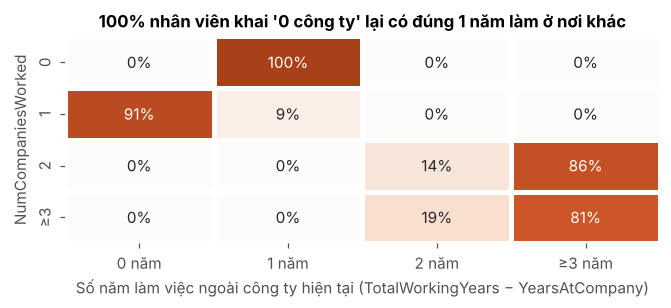

Số bản ghi NumCompaniesWorked=0: 197


In [8]:
# 2.2b Điều tra sâu vi phạm của NumCompaniesWorked: chênh lệch (TotalWorkingYears − YearsAtCompany) theo từng mức
gap = (df.TotalWorkingYears - df.YearsAtCompany)
ct = pd.crosstab(df.NumCompaniesWorked.clip(upper=3), gap.clip(upper=3), normalize="index")
ct.index = ["0", "1", "2", "≥3"]; ct.columns = ["0 năm", "1 năm", "2 năm", "≥3 năm"]
fig, ax = plt.subplots(figsize=(6.2, 2.9))
sns.heatmap(ct, annot=True, fmt=".0%", cmap=CMAP_RATE, cbar=False, linewidths=2, linecolor="white", ax=ax)
ax.set_xlabel("Số năm làm việc ngoài công ty hiện tại (TotalWorkingYears − YearsAtCompany)")
ax.set_ylabel("NumCompaniesWorked")
ax.set_title("100% nhân viên khai '0 công ty' lại có đúng 1 năm làm ở nơi khác")
save(fig, "fig02_numcompanies")
print("Số bản ghi NumCompaniesWorked=0:", (df.NumCompaniesWorked == 0).sum())

**Diễn giải.** Ở mức `NumCompaniesWorked = 1`, 91% bản ghi có tổng năm làm = năm tại công ty → biến này **đếm cả công ty hiện tại**. Theo logic đó, “0 công ty” là bất khả. Cả 197 bản ghi mức 0 đều lệch *đúng 1 năm* — một mẫu hình quá đều để là lỗi nhập liệu ngẫu nhiên, gợi ý **lỗi mã hóa có hệ thống** của bộ sinh dữ liệu. **Quyết định:** *không* tự ý sửa giá trị (không biết giá trị đúng), giữ nguyên nhưng gắn cờ `NCW_inconsistent` và ghi nhận ở phần giới hạn. Biến này cũng không có ý nghĩa thống kê với Attrition (mục 3.9) nên rủi ro thấp.

Tương quan Spearman với MonthlyIncome:


DailyRate      0.016
HourlyRate    -0.020
MonthlyRate    0.054
Name: MonthlyIncome, dtype: float64


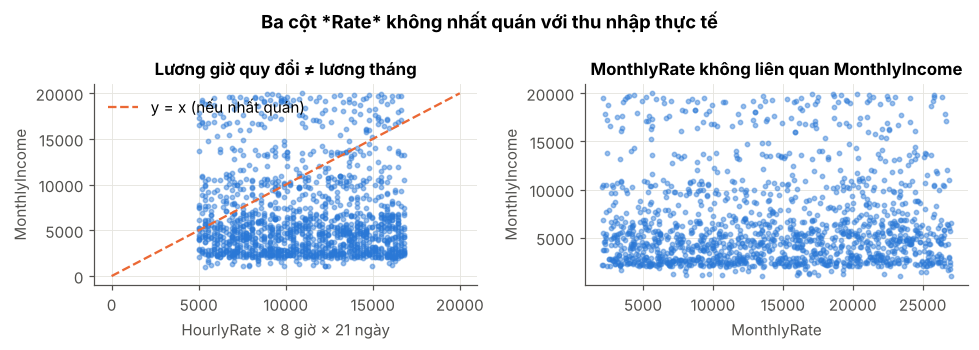

DailyRate: Mann-Whitney p = 0.029
HourlyRate: Mann-Whitney p = 0.798
MonthlyRate: Mann-Whitney p = 0.559


In [9]:
# 2.3 Kiểm tra ba cột "Rate" không có mô tả: nếu là đơn giá lương thì phải tương quan mạnh với MonthlyIncome
df["NCW_inconsistent"] = (df.NumCompaniesWorked == 0).astype(int)
rate_cols = ["DailyRate", "HourlyRate", "MonthlyRate"]
print("Tương quan Spearman với MonthlyIncome:")
print(df[rate_cols + ["MonthlyIncome"]].corr("spearman")["MonthlyIncome"].drop("MonthlyIncome").round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].scatter(df.HourlyRate * 8 * 21, df.MonthlyIncome, s=8, alpha=0.45, color=C_STAY)
lim = [0, 20000]; axes[0].plot(lim, lim, color=C_LEAVE, lw=1.5, ls="--", label="y = x (nếu nhất quán)")
axes[0].set_xlabel("HourlyRate × 8 giờ × 21 ngày"); axes[0].set_ylabel("MonthlyIncome")
axes[0].set_title("Lương giờ quy đổi ≠ lương tháng"); axes[0].legend(frameon=False)
axes[1].scatter(df.MonthlyRate, df.MonthlyIncome, s=8, alpha=0.45, color=C_STAY)
axes[1].set_xlabel("MonthlyRate"); axes[1].set_ylabel("MonthlyIncome")
axes[1].set_title("MonthlyRate không liên quan MonthlyIncome")
fig.suptitle("Ba cột *Rate* không nhất quán với thu nhập thực tế", fontweight="bold")
save(fig, "fig03_rates")

# Kiểm tra thêm: các cột Rate có khác biệt giữa nhóm nghỉ và ở lại không?
for c in rate_cols:
    p = stats.mannwhitneyu(df.loc[df.AttritionFlag == 1, c], df.loc[df.AttritionFlag == 0, c]).pvalue
    print(f"{c}: Mann-Whitney p = {p:.3f}")

**Quyết định:** tương quan ≈ 0 và phân phối gần đều → ba cột *Rate* nhiều khả năng là **số ngẫu nhiên** của bộ sinh dữ liệu, không phải thông tin lương. `DailyRate` có p = 0,029 nhưng đây là kết quả đáng ngờ: biến không có ngữ nghĩa rõ, hai cột “anh em” không có ý nghĩa, và với 3 kiểm định thì ngưỡng Bonferroni là 0,017 → không vượt qua. Đưa vào mô hình chỉ thêm nhiễu → **loại khỏi mô hình** (vẫn giữ trong phần mô tả). Đây là ví dụ cho nguyên tắc *“kiểm tra ngữ nghĩa trước khi tin vào cột số”*.

## 2.4 Ngoại lệ (outliers) — phương pháp IQR

In [10]:
# 2.4 Phát hiện outlier bằng quy tắc IQR (Q1 − 1,5·IQR; Q3 + 1,5·IQR) cho các biến liên tục / đếm
cont = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager", "NumCompaniesWorked", "Age", "DistanceFromHome"]
rows = []
for c in cont:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo, 1), round(hi, 1), n_out, round(n_out / len(df) * 100, 1),
                 round(df[c].skew(), 2), round(df[c].mean(), 1), df[c].median()])
outlier_tbl = pd.DataFrame(rows, columns=["Biến", "Cận dưới", "Cận trên", "Số outlier", "%", "Skewness", "Mean", "Median"])
outlier_tbl.sort_values("Số outlier", ascending=False)

,Biến,Cận dưới,Cận trên,Số outlier,%,Skewness,Mean,Median
0,MonthlyIncome,-5291.0,16581.0,114,7.8,1.37,6502.9,4919.0
4,YearsSinceLastPromotion,-4.5,7.5,107,7.3,1.98,2.2,1.0
2,YearsAtCompany,-6.0,18.0,104,7.1,1.76,7.0,5.0
1,TotalWorkingYears,-7.5,28.5,63,4.3,1.12,11.3,10.0
6,NumCompaniesWorked,-3.5,8.5,52,3.5,1.03,2.7,2.0
3,YearsInCurrentRole,-5.5,14.5,21,1.4,0.92,4.2,3.0
5,YearsWithCurrManager,-5.5,14.5,14,1.0,0.83,4.1,3.0
7,Age,10.5,62.5,0,0.0,0.41,36.9,36.0
8,DistanceFromHome,-16.0,32.0,0,0.0,0.96,9.2,7.0


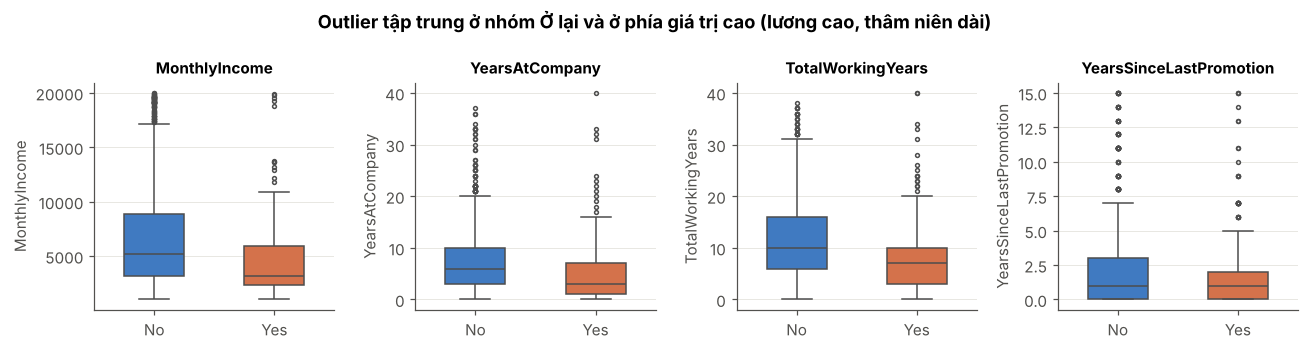

Phân bố JobLevel của 114 outlier thu nhập: {4: 45, 5: 69}


In [11]:
# 2.4b Trực quan hóa outlier: boxplot theo nhóm Attrition — outlier có phải "lỗi" hay là một phân khúc thật?
show = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears", "YearsSinceLastPromotion"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, c in zip(axes, show):
    sns.boxplot(data=df, x="Attrition", y=c, order=["No", "Yes"], palette=[C_STAY, C_LEAVE],
                width=0.5, fliersize=2.5, linewidth=1, ax=ax)
    ax.set_xlabel(""); ax.set_title(c, fontsize=10)
fig.suptitle("Outlier tập trung ở nhóm Ở lại và ở phía giá trị cao (lương cao, thâm niên dài)", fontweight="bold")
save(fig, "fig04_outliers")

# Outlier thu nhập có tương ứng với cấp bậc cao không? (nếu có → giá trị hợp lệ, không phải lỗi)
q3, q1 = df.MonthlyIncome.quantile([.75, .25]); hi = q3 + 1.5 * (q3 - q1)
print("Phân bố JobLevel của 114 outlier thu nhập:", df.loc[df.MonthlyIncome > hi, "JobLevel"].value_counts().sort_index().to_dict())

**Quyết định và lý do.** Outlier thu nhập đều thuộc JobLevel 4–5 (quản lý cấp cao) → đây là **giá trị thật, không phải lỗi**. Xóa đi sẽ (i) mất ~7,8% mẫu, (ii) xóa nhầm nguyên một phân khúc nhân sự cấp cao — vốn là nhóm có tỷ lệ nghỉ thấp nhất, làm lệch kết luận. Vì vậy nhóm **không xóa, không cắt (cap)**, mà xử lý *độ lệch* bằng **biến đổi log1p** cho các biến có skewness > 0,75 khi đưa vào mô hình tuyến tính; Random Forest dựa trên phân ngưỡng nên không nhạy với outlier.

## 2.5 Chiến lược giá trị thiếu: vì sao Median thay vì Mean?

In [12]:
# 2.5 Dữ liệu hiện không thiếu, nhưng pipeline vẫn cài SimpleImputer(median) để chạy an toàn với dữ liệu mới.
# Minh chứng lý do chọn median: với phân phối lệch phải, mean bị kéo lên bởi nhóm lương cao.
s = df.MonthlyIncome
print(f"MonthlyIncome: mean = {s.mean():,.0f} | median = {s.median():,.0f} | skew = {s.skew():.2f}")
print(f"Tỷ lệ nhân viên có lương < mean: {(s < s.mean()).mean():.1%}  → mean không đại diện cho 'nhân viên điển hình'")

# Thí nghiệm nhỏ: xóa ngẫu nhiên 10% giá trị, điền bằng mean vs median, so sai số tuyệt đối trung vị
rng = np.random.default_rng(SEED)
idx = rng.choice(len(s), size=int(0.1 * len(s)), replace=False)
true = s.iloc[idx]
for name, val in [("mean", s.drop(s.index[idx]).mean()), ("median", s.drop(s.index[idx]).median())]:
    print(f"Điền bằng {name:6s}: median |sai số| = {np.median(np.abs(true - val)):,.0f}")

MonthlyIncome: mean = 6,503 | median = 4,919 | skew = 1.37
Tỷ lệ nhân viên có lương < mean: 66.5%  → mean không đại diện cho 'nhân viên điển hình'
Điền bằng mean  : median |sai số| = 3,319
Điền bằng median: median |sai số| = 2,123


## 2.6 Kỹ thuật đặc trưng (feature engineering)

In [13]:
# 2.6 Tạo biến mới có ý nghĩa nghiệp vụ
# (a) Lương tương đối trong cùng cấp bậc: so với trung vị của JobLevel → đo "công bằng nội bộ"
df["RelPayInLevel"] = df.MonthlyIncome / df.groupby("JobLevel").MonthlyIncome.transform("median")
# (b) Số năm bình quân mỗi công ty: đo mức độ "nhảy việc" trong quá khứ
df["YearsPerCompany"] = df.TotalWorkingYears / (df.NumCompaniesWorked + 1)
# (c) Tỷ lệ thời gian chưa được thăng chức trên thâm niên tại công ty
df["PromotionStagnation"] = df.YearsSinceLastPromotion / (df.YearsAtCompany + 1)
# (d) Chỉ số hài lòng tổng hợp (trung bình 4 thang khảo sát 1-4)
sat_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"]
df["SatisfactionIndex"] = df[sat_cols].mean(axis=1)
# (e) Nhóm tuổi và nhóm thâm niên — chỉ dùng cho EDA
df["AgeGroup"] = pd.cut(df.Age, [17, 25, 30, 35, 45, 60], labels=["18-25", "26-30", "31-35", "36-45", "46-60"])
df["TenureGroup"] = pd.cut(df.YearsAtCompany, [-1, 1, 2, 5, 10, 40], labels=["0-1", "2", "3-5", "6-10", ">10"])
df[["RelPayInLevel", "YearsPerCompany", "PromotionStagnation", "SatisfactionIndex"]].describe().round(2)

,RelPayInLevel,YearsPerCompany,PromotionStagnation,SatisfactionIndex
count,1470.00,1470.00,1470.00,1470.00
mean,1.02,4.19,0.24,2.73
std,0.25,4.04,0.27,0.51
min,0.38,0.00,0.00,1.00
25%,0.86,1.60,0.00,2.50
50%,1.00,3.00,0.14,2.75
75%,1.12,5.00,0.43,3.00
max,1.87,38.00,0.92,4.00


## 2.7 Mã hóa (encoding) và chuẩn hóa (scaling) — lựa chọn có lý do

| Nhóm biến | Kỹ thuật | Lý do |
|---|---|---|
| Nhị phân (`OverTime`, `Gender`) | Map 0/1 | Không tạo thêm chiều |
| `BusinessTravel` | **Ordinal** 0/1/2 (Non < Rarely < Frequently) | Có thứ tự tự nhiên theo tần suất đi công tác |
| Danh nghĩa (`Department`, `JobRole`, `EducationField`, `MaritalStatus`) | **One-Hot** (`drop='first'` cho Logistic) | Không có thứ tự; Label Encoding sẽ áp đặt thứ tự giả (VD: Sales > HR) |
| `JobLevel`, `Education`, `StockOptionLevel` | **Giữ dạng số** | Bảo toàn thứ tự, ít tham số |
| 5 thang khảo sát 1–4 | **Giữ dạng số + thêm cờ `_is1` (mức = 1)** | Mục 3.5 cho thấy rủi ro tập trung ở mức thấp nhất (hiệu ứng ngưỡng) và `WorkLifeBalance` không đơn điệu; chỉ dùng số sẽ ép quan hệ thành tuyến tính |
| Biến lệch (skew > 0,75) | **log1p** rồi **StandardScaler** | Giảm ảnh hưởng đuôi phải; Logistic có phạt L2 cần các biến cùng thang để hệ số so sánh được |
| Random Forest | Không scale | Mô hình cây bất biến với phép biến đổi đơn điệu |

Không dùng MinMaxScaler vì nhạy với outlier đã giữ lại ở mục 2.4.

In [14]:
# 2.7 Mã hóa biến nhị phân và thứ bậc
df["OverTime_bin"] = (df.OverTime == "Yes").astype(int)
df["Gender_bin"] = (df.Gender == "Male").astype(int)
df["BusinessTravel_ord"] = df.BusinessTravel.map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
# Cờ ngưỡng cho 5 thang khảo sát: 1 nếu nhân viên chấm mức thấp nhất (bắt hiệu ứng ngưỡng, xem mục 3.5)
survey_cols = ["EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", "WorkLifeBalance", "RelationshipSatisfaction"]
for c in survey_cols:
    df[f"{c}_is1"] = (df[c] == 1).astype(int)

nominal = ["Department", "JobRole", "EducationField", "MaritalStatus"]
numeric = ["Age", "DistanceFromHome", "Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
           "JobSatisfaction", "MonthlyIncome", "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
           "RelationshipSatisfaction", "StockOptionLevel", "TotalWorkingYears", "TrainingTimesLastYear",
           "WorkLifeBalance", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion",
           "YearsWithCurrManager", "OverTime_bin", "Gender_bin", "BusinessTravel_ord",
           "RelPayInLevel", "YearsPerCompany", "PromotionStagnation", "NCW_inconsistent"] + [f"{c}_is1" for c in survey_cols]
skewed = [c for c in numeric if df[c].nunique() > 5 and df[c].skew() > 0.75]
print("Biến sẽ log1p:", skewed)
skew_cmp = pd.DataFrame({"skew trước": df[skewed].skew(), "skew sau log1p": np.log1p(df[skewed]).skew()}).round(2)
skew_cmp

Biến sẽ log1p: ['DistanceFromHome', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'RelPayInLevel', 'YearsPerCompany', 'PromotionStagnation']


,skew trước,skew sau log1p
DistanceFromHome,0.96,-0.03
MonthlyIncome,1.37,0.29
NumCompaniesWorked,1.03,0.09
PercentSalaryHike,0.82,0.51
TotalWorkingYears,1.12,-0.62
YearsAtCompany,1.76,-0.21
YearsInCurrentRole,0.92,-0.38
YearsSinceLastPromotion,1.98,0.72
YearsWithCurrManager,0.83,-0.36
RelPayInLevel,0.83,0.29


# GIAI ĐOẠN 3 — Phân tích, kiểm định giả thuyết và trực quan hóa
## 3.0 Khung giả thuyết
| # | Giả thuyết (H₁) | Cơ sở nghiệp vụ | Kiểm định |
|---|---|---|---|
| H1 | Làm thêm giờ làm tăng nghỉ việc | Kiệt sức (burnout) | χ², Cramér's V |
| H2 | Người nghỉ có thu nhập thấp hơn — kể cả *trong cùng cấp bậc* | Lý thuyết công bằng (Equity theory) | Mann-Whitney U |
| H3 | Rủi ro cao nhất ở giai đoạn đầu sự nghiệp/đầu nhiệm kỳ | Chi phí chuyển việc thấp khi trẻ | χ² |
| H4 | Mức hài lòng càng thấp, nghỉ việc càng cao | Mô hình Herzberg | χ² |
| H5 | Gắn kết tài chính dài hạn (cổ phiếu) giữ chân nhân viên | “Golden handcuffs” | χ² theo phân tầng |
| H6 | Vai trò và tần suất công tác ảnh hưởng nghỉ việc | Đặc thù công việc | χ² |
| H7 | Hiệu suất cao/tăng lương cao giúp giữ người | Pay-for-performance | χ², Mann-Whitney |

Mức ý nghĩa α = 0,05. Vì nhóm thực hiện nhiều kiểm định cùng lúc, p-value được **hiệu chỉnh Bonferroni** ở mục 3.9 (so p với α/m, m = số kiểm định).

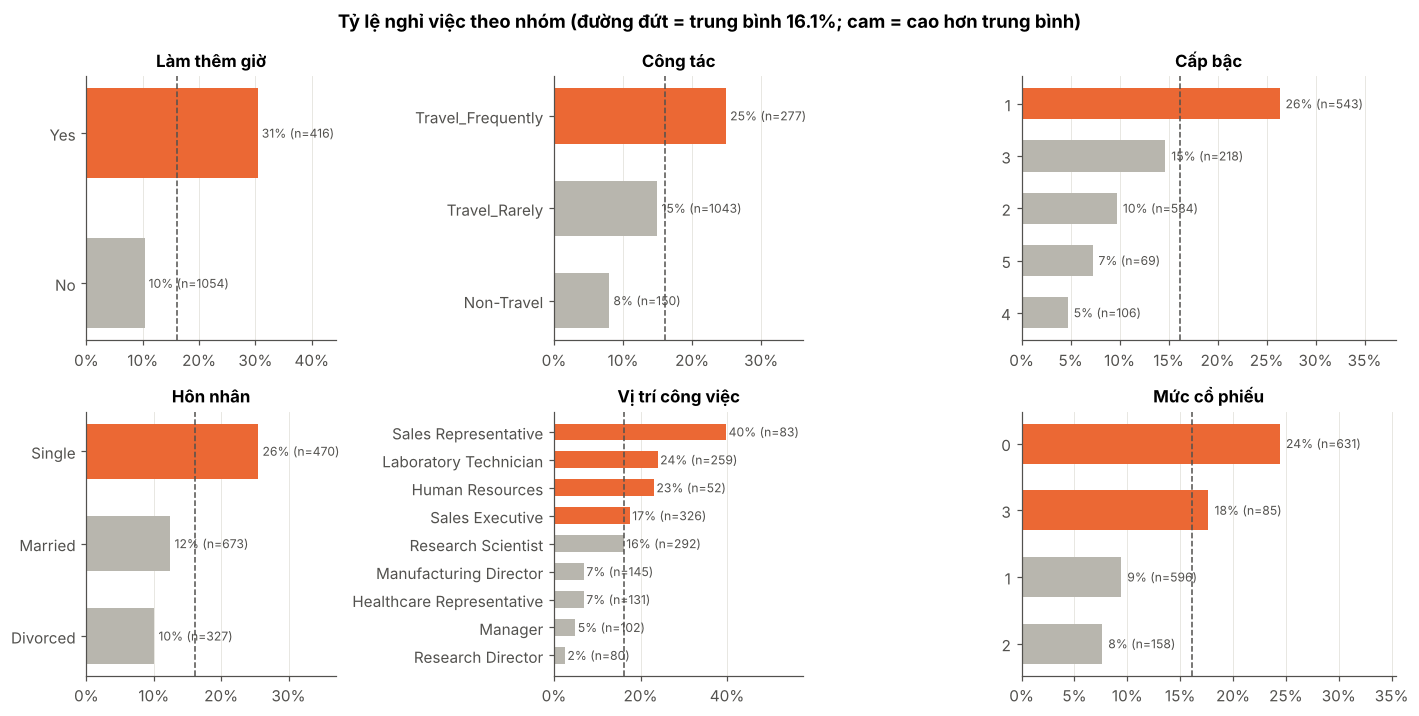

In [15]:
# 3.1 Tổng quan: tỷ lệ nghỉ việc theo các biến phân loại chính (sắp xếp giảm dần, kèm cỡ mẫu)
base = df.AttritionFlag.mean()
panels = [("OverTime", "Làm thêm giờ"), ("MaritalStatus", "Hôn nhân"), ("BusinessTravel", "Công tác"),
          ("JobRole", "Vị trí công việc"), ("JobLevel", "Cấp bậc"), ("StockOptionLevel", "Mức cổ phiếu")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, (col, title) in zip(axes.T.flatten(), panels):
    r = attr_rate(df, col).sort_values("rate")
    colors = [C_LEAVE if v > base else C_GREY for v in r.rate]
    ax.barh(r.index.astype(str), r.rate, color=colors, height=0.6)
    for i, (v, n) in enumerate(zip(r.rate, r.n)):
        ax.text(v + 0.006, i, f"{v:.0%} (n={n})", va="center", fontsize=8, color=C_INK)
    ax.axvline(base, color=C_INK, lw=1, ls="--")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_xlim(0, max(r.rate) * 1.45)
    ax.set_title(title); ax.grid(axis="y", visible=False)
fig.suptitle(f"Tỷ lệ nghỉ việc theo nhóm (đường đứt = trung bình {base:.1%}; cam = cao hơn trung bình)", fontweight="bold")
save(fig, "fig05_overview")

## 3.2 H1 — Làm thêm giờ (OverTime)

Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127 
χ² = 87.6, p = 8.2e-21, Cramér's V = 0.246
Rủi ro tương đối (RR) = 2.93


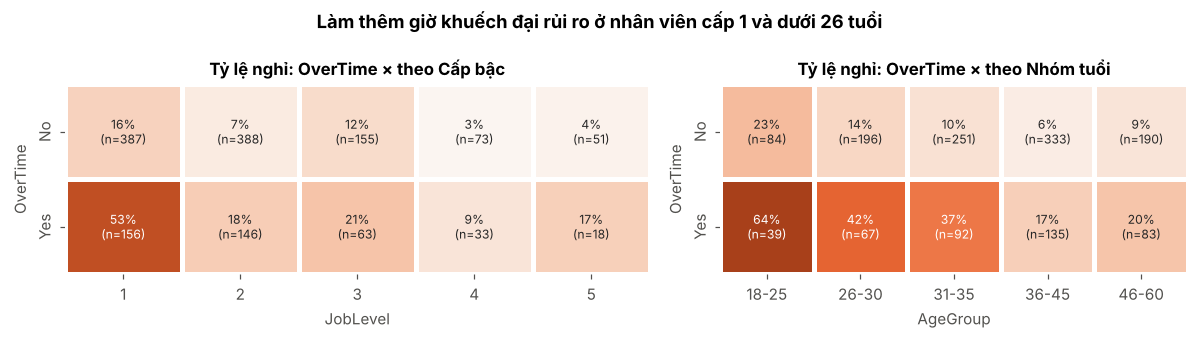

In [16]:
# 3.2 H1: kiểm định χ² độc lập giữa OverTime và Attrition + phân tích tương tác với JobLevel
tab = pd.crosstab(df.OverTime, df.Attrition)
chi2, p, dof, _ = stats.chi2_contingency(tab)
r = attr_rate(df, "OverTime")
print(tab, f"\nχ² = {chi2:.1f}, p = {p:.1e}, Cramér's V = {cramers_v(tab):.3f}")
print(f"Rủi ro tương đối (RR) = {r.rate['Yes'] / r.rate['No']:.2f}")

# Tương tác: OverTime × JobLevel và OverTime × nhóm tuổi
fig, axes = plt.subplots(1, 2, figsize=(11, 3.1), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, col, ttl in [(axes[0], "JobLevel", "theo Cấp bậc"), (axes[1], "AgeGroup", "theo Nhóm tuổi")]:
    rate = df.pivot_table(index="OverTime", columns=col, values="AttritionFlag", aggfunc="mean", observed=True)
    n = df.pivot_table(index="OverTime", columns=col, values="AttritionFlag", aggfunc="size", observed=True)
    annot = rate.map(lambda v: f"{v:.0%}") + "\n(n=" + n.astype(str) + ")"
    sns.heatmap(rate, annot=annot, fmt="", cmap=CMAP_RATE, vmin=0, vmax=0.6, cbar=False,
                linewidths=2, linecolor="white", annot_kws={"fontsize": 8}, ax=ax)
    ax.set_title(f"Tỷ lệ nghỉ: OverTime × {ttl}"); ax.set_ylabel("OverTime")
fig.suptitle("Làm thêm giờ khuếch đại rủi ro ở nhân viên cấp 1 và dưới 26 tuổi", fontweight="bold")
save(fig, "fig06_overtime")

## 3.3 H2 — Thu nhập và công bằng nội bộ

MonthlyIncome: median nghỉ = 3,202.00 | median ở lại = 5,204.00 | p = 3.0e-14
RelPayInLevel: median nghỉ = 0.96 | median ở lại = 1.01 | p = 8.1e-03

Trong từng cấp bậc:
 JobLevel   n  n nghỉ  Median nghỉ  Median ở lại      p  p_Bonferroni                                        Kết luận
        1 543     143       2437.0        2719.0 0.0004        0.0021                                    Có khác biệt
        2 534      52       5346.0        5334.5 0.3072        1.0000                                 Không khác biệt
        3 218      32       9887.0        9982.5 0.1605        0.8026                                 Không khác biệt
        4 106       5      13194.0       16307.0 0.0040        0.0201 Có ý nghĩa nhưng n nghỉ < 20 → không đủ tin cậy
        5  69       5      19545.0       19199.5 0.2057        1.0000                                 Không khác biệt


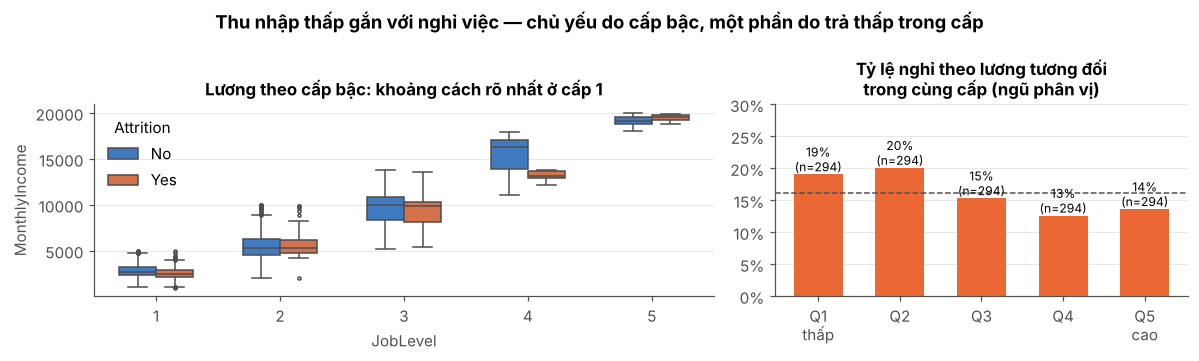

           rate    n
RelPayQ             
Q1\nthấp  0.190  294
Q2        0.201  294
Q3        0.153  294
Q4        0.126  294
Q5\ncao   0.136  294


In [17]:
# 3.3 H2: so sánh thu nhập giữa hai nhóm bằng Mann-Whitney U (phi tham số vì lương lệch phải)
def mwu(col, frame=df):
    # Trả về trung vị của nhóm nghỉ, nhóm ở lại và p-value của kiểm định Mann-Whitney U
    a, b = frame.loc[frame.AttritionFlag == 1, col], frame.loc[frame.AttritionFlag == 0, col]
    return a.median(), b.median(), stats.mannwhitneyu(a, b).pvalue

for col in ["MonthlyIncome", "RelPayInLevel"]:
    m1, m0, p = mwu(col)
    print(f"{col}: median nghỉ = {m1:,.2f} | median ở lại = {m0:,.2f} | p = {p:.1e}")
# Trong từng cấp bậc: 5 kiểm định cùng lúc → báo cáo số người nghỉ và hiệu chỉnh Bonferroni (×5)
lv = []
for jl in range(1, 6):
    sub_l = df[df.JobLevel == jl]
    m1, m0, p = mwu("MonthlyIncome", sub_l)
    lv.append([jl, len(sub_l), int(sub_l.AttritionFlag.sum()), m1, m0, p])
lv = pd.DataFrame(lv, columns=["JobLevel", "n", "n nghỉ", "Median nghỉ", "Median ở lại", "p"])
lv["p_Bonferroni"] = bonferroni(lv.p)
lv["Kết luận"] = np.where((lv.p_Bonferroni < 0.05) & (lv["n nghỉ"] >= 20), "Có khác biệt",
                 np.where(lv.p_Bonferroni < 0.05, "Có ý nghĩa nhưng n nghỉ < 20 → không đủ tin cậy", "Không khác biệt"))
print("\nTrong từng cấp bậc:")
print(lv.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1.5, 1]})
sns.boxplot(data=df, x="JobLevel", y="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"],
            palette=[C_STAY, C_LEAVE], fliersize=2, linewidth=1, width=0.6, ax=axes[0])
axes[0].set_title("Lương theo cấp bậc: khoảng cách rõ nhất ở cấp 1"); axes[0].legend(title="Attrition", frameon=False)
# Tỷ lệ nghỉ theo ngũ phân vị lương tương đối trong cấp
df["RelPayQ"] = pd.qcut(df.RelPayInLevel, 5, labels=["Q1\nthấp", "Q2", "Q3", "Q4", "Q5\ncao"])
r = attr_rate(df, "RelPayQ")
axes[1].bar(range(5), r.rate, color=C_LEAVE, width=0.6)
for i, (v, n) in enumerate(zip(r.rate, r.n)):
    axes[1].text(i, v + 0.005, f"{v:.0%}\n(n={n})", ha="center", fontsize=8)
axes[1].axhline(base, color=C_INK, ls="--", lw=1)
axes[1].set_xticks(range(5)); axes[1].set_xticklabels(r.index); axes[1].grid(axis="x", visible=False)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); axes[1].set_ylim(0, 0.3)
axes[1].set_title("Tỷ lệ nghỉ theo lương tương đối\ntrong cùng cấp (ngũ phân vị)"); axes[1].set_xlabel("")
fig.suptitle("Thu nhập thấp gắn với nghỉ việc — chủ yếu do cấp bậc, một phần do trả thấp trong cấp", fontweight="bold")
save(fig, "fig07_income")
print(r.round(3))

## 3.4 H3 — Giai đoạn sự nghiệp: tuổi và thâm niên

AgeGroup χ² p = 2.7e-12, V = 0.202
TenureGroup χ² p = 8.9e-16, V = 0.228


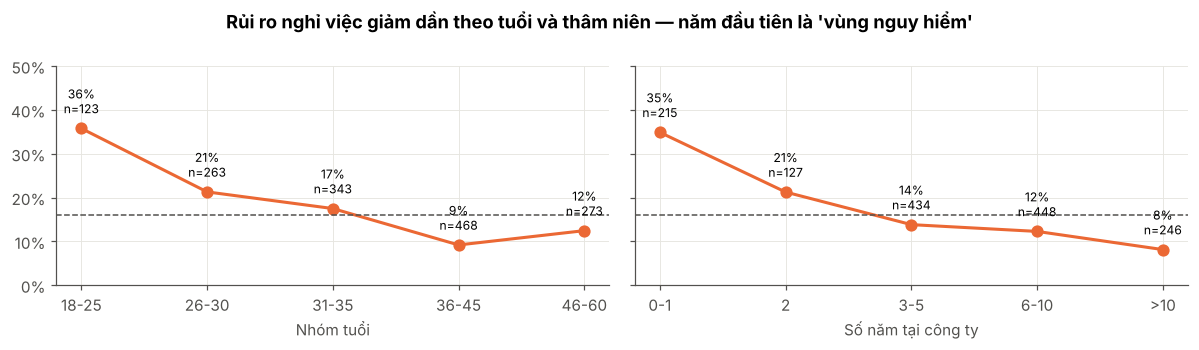

In [18]:
# 3.4 H3: tỷ lệ nghỉ theo nhóm tuổi và nhóm thâm niên, kèm cỡ mẫu từng nhóm
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, col, xl in [(axes[0], "AgeGroup", "Nhóm tuổi"), (axes[1], "TenureGroup", "Số năm tại công ty")]:
    r = attr_rate(df, col)
    ax.plot(range(len(r)), r.rate, color=C_LEAVE, marker="o", ms=7, lw=2)
    for i, (v, n) in enumerate(zip(r.rate, r.n)):
        ax.annotate(f"{v:.0%}\nn={n}", (i, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
    ax.axhline(base, color=C_INK, ls="--", lw=1)
    ax.set_xticks(range(len(r))); ax.set_xticklabels(r.index); ax.set_xlabel(xl)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, 0.5)
    tab = pd.crosstab(df[col], df.Attrition); print(col, f"χ² p = {stats.chi2_contingency(tab)[1]:.1e}, V = {cramers_v(tab):.3f}")
fig.suptitle("Rủi ro nghỉ việc giảm dần theo tuổi và thâm niên — năm đầu tiên là 'vùng nguy hiểm'", fontweight="bold")
save(fig, "fig08_career")

## 3.5 H4 — Mức độ hài lòng và gắn kết

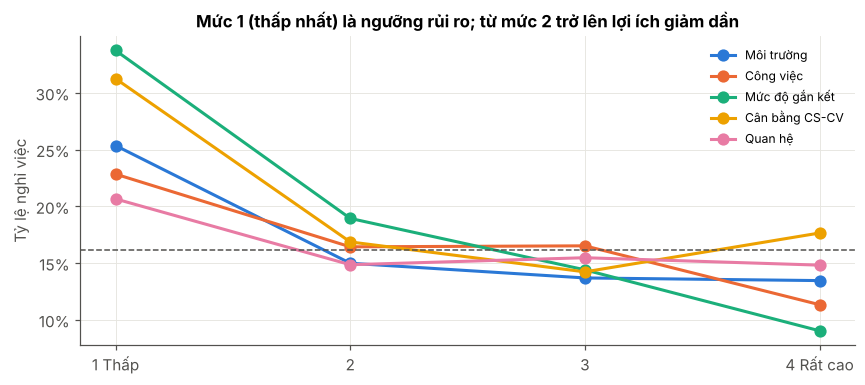

      Thang đo  Tỷ lệ nghỉ @1  Tỷ lệ nghỉ @4   χ² p  Cramér V  p (mức 1 vs 2–4)
    Môi trường         0.2535         0.1345 0.0001    0.1237            0.0000
     Công việc         0.2284         0.1133 0.0006    0.1091            0.0007
Mức độ gắn kết         0.3373         0.0903 0.0000    0.1392            0.0000
Cân bằng CS-CV         0.3125         0.1765 0.0010    0.1054            0.0003
       Quan hệ         0.2065         0.1481 0.1550    0.0597            0.0293


,Thang đo,Tỷ lệ nghỉ @1,Tỷ lệ nghỉ @4,χ² p,Cramér V,p (mức 1 vs 2–4)
0,Môi trường,0.2535,0.1345,0.0001,0.1237,0.0000
1,Công việc,0.2284,0.1133,0.0006,0.1091,0.0007
2,Mức độ gắn kết,0.3373,0.0903,0.0000,0.1392,0.0000
3,Cân bằng CS-CV,0.3125,0.1765,0.0010,0.1054,0.0003
4,Quan hệ,0.2065,0.1481,0.1550,0.0597,0.0293


In [19]:
# 3.5 H4: tỷ lệ nghỉ theo từng mức của 5 thang khảo sát (1 = thấp nhất, 4 = cao nhất)
surveys = ["EnvironmentSatisfaction", "JobSatisfaction", "JobInvolvement", "WorkLifeBalance", "RelationshipSatisfaction"]
labels = ["Môi trường", "Công việc", "Mức độ gắn kết", "Cân bằng CS-CV", "Quan hệ"]
cats = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # bảng màu phân loại cố định, đã kiểm định CVD
fig, ax = plt.subplots(figsize=(8, 3.6))
res = []
for c, lab, col in zip(surveys, labels, cats):
    r = attr_rate(df, c)
    ax.plot(r.index, r.rate, marker="o", ms=7, lw=2, color=col)
    tab = pd.crosstab(df[c], df.Attrition)                           # χ² trên cả 4 mức
    tab1 = pd.crosstab(df[c] == 1, df.Attrition)                     # χ² 2×2: mức 1 so với các mức 2–4
    res.append([lab, r.rate.iloc[0], r.rate.iloc[-1], stats.chi2_contingency(tab)[1], cramers_v(tab),
                stats.chi2_contingency(tab1)[1]])
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["1 Thấp", "2", "3", "4 Rất cao"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylabel("Tỷ lệ nghỉ việc")
ax.axhline(base, color=C_INK, ls="--", lw=1)
ax.legend(labels, frameon=False, fontsize=8, loc="upper right")
ax.set_title("Mức 1 (thấp nhất) là ngưỡng rủi ro; từ mức 2 trở lên lợi ích giảm dần")
save(fig, "fig09_satisfaction")
sat_tbl = pd.DataFrame(res, columns=["Thang đo", "Tỷ lệ nghỉ @1", "Tỷ lệ nghỉ @4", "χ² p", "Cramér V",
                                    "p (mức 1 vs 2–4)"])
print(sat_tbl.round(4).to_string(index=False))
sat_tbl.round(4)